# Expectation-maximization algorithm

## Introduction

In this report we segment a 2D axial MR brain slice into three tissue classes (cerebrospinal fluid, grey matter and white matter) by fitting a generative model to the image intensities. We use the bias-field-corrected image (`correctedData.mat`), restricted to brain pixels by the mask.

**Model.** Each pixel intensity $d_n$ is assumed to come from one of $K = 3$ classes. Class $k$ occurs with prior probability $\pi_k$ and produces intensities according to a Gaussian $\mathcal{N}(d_n \mid \mu_k, \sigma_k^2)$. Assuming independent pixels, this gives a Gaussian mixture model with log likelihood

$$ \log p(\mathbf{d} \mid \theta) = \sum_{n=1}^{N} \log \sum_{k=1}^{K} \pi_k \, \mathcal{N}(d_n \mid \mu_k, \sigma_k^2), \qquad \theta = \{\mu_k, \sigma_k^2, \pi_k\}_{k=1}^{K}. $$

**Expectation-maximization.** The parameters are estimated by maximizing this log likelihood with the EM algorithm, which alternates two steps:

- *E-step:* compute the posterior probability (weight) of each class for each pixel, using the current estimate $\tilde\theta$:
$$ w_{n,k} = \frac{\mathcal{N}(d_n \mid \tilde\mu_k, \tilde\sigma_k^2)\,\tilde\pi_k}{\sum_{k'} \mathcal{N}(d_n \mid \tilde\mu_{k'}, \tilde\sigma_{k'}^2)\,\tilde\pi_{k'}} $$
- *M-step:* update the parameters as weighted averages:
$$ \tilde\mu_k = \frac{\sum_n w_{n,k}\, d_n}{\sum_n w_{n,k}}, \qquad \tilde\sigma_k^2 = \frac{\sum_n w_{n,k}\,(d_n - \tilde\mu_k)^2}{\sum_n w_{n,k}}, \qquad \tilde\pi_k = \frac{\sum_n w_{n,k}}{N}. $$

Using Jensen's inequality, the weights define a lower bound $Q(\theta \mid \tilde\theta)$ on the log likelihood that touches it at $\tilde\theta$. The M-step maximizes this bound, so the log likelihood can never decrease from one iteration to the next. Tasks 6–8 illustrate this lower bound directly.


### Input data and code hints
Import Python libraries:

In [1]:
import numpy as np
import scipy
from scipy.io import loadmat
from scipy import signal
import warnings
warnings.filterwarnings("ignore")
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm
import matplotlib.mlab as mlab
%matplotlib inline

## Task 1: Image data


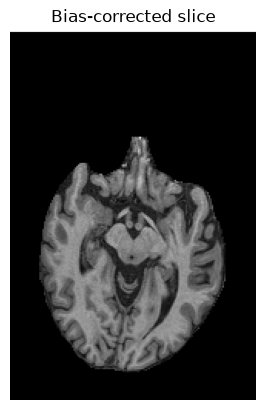

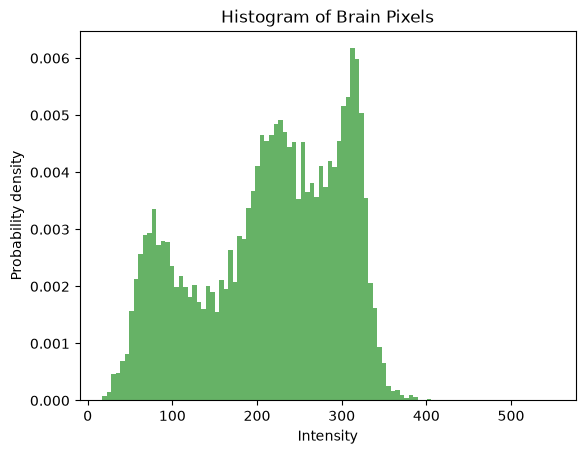

In [2]:
# Load data
mat = loadmat("correctedData.mat")
data = mat["correctedData"]

# Disregard background pixels by clipping 0
brain_pixels = data[data > 0]

plt.imshow(data, cmap='gray'); plt.title("Bias-corrected slice"); plt.axis('off'); plt.show()

# Plot histogram
counts, bins, patches = plt.hist(brain_pixels, bins=100, density=True, alpha=0.6, color='g')
plt.title("Histogram of Brain Pixels")
plt.xlabel("Intensity")
plt.ylabel("Probability density")
plt.show()

### Results

The first figure shows the bias-field-corrected axial slice. Non-brain tissue has been removed by the mask, so all background pixels are zero. The image is T1-weighted: white matter appears bright, grey matter (the cortical ribbon and deep grey structures) appears intermediate, and cerebrospinal fluid (the ventricles and the spaces around the brain) appears dark.

The histogram shows the intensities of the $N = 13\,272$ brain pixels (background pixels with intensity 0 are excluded), using 100 bins and normalized to unit area so that it can be compared directly with probability densities. It has three overlapping peaks, which correspond to the three tissue classes:

- a low-intensity peak around 80, corresponding to cerebrospinal fluid,
- an intermediate peak around 225, corresponding to grey matter,
- a high-intensity peak around 310, corresponding to white matter.

The peaks overlap considerably, especially grey and white matter, so the tissues cannot be separated by simple thresholds without ambiguity. This motivates modelling the histogram as a mixture of three Gaussian distributions. A long, almost invisible tail extends to about 550 due to a few very bright outlier pixels.

## Task 2: Initialize Gaussian-Mixture Model

In [3]:
# Compute min, max, and interval width
min_val = np.min(brain_pixels)
max_val = np.max(brain_pixels)
interval_width = (max_val - min_val) / 3

# Initialize means to the centers of the 3 intervals
mu = [min_val + interval_width * 0.5, 
      min_val + interval_width * 1.5, 
      min_val + interval_width * 2.5]

# Initialize variances to the square of the interval width
variance = [interval_width**2] * 3
sigma = np.sqrt(variance)

# Initialize prior weights to 1/3 each
pi = [1/3, 1/3, 1/3]

### Results

To start EM, the Gaussian mixture model needs initial parameter values. Following the prescribed rule, we compute the minimum and maximum intensity of the brain pixels, $d_{\min} = 17.1$ and $d_{\max} = 549.7$, and divide this range into three equally wide intervals of width

$$ \Delta = \frac{d_{\max} - d_{\min}}{3} = 177.5. $$

Each Gaussian is then initialized as follows:

- **Means:** the centres of the three intervals, $\mu_k = d_{\min} + (k - \tfrac{1}{2})\,\Delta$, giving $\mu_1 = 105.8$, $\mu_2 = 283.4$ and $\mu_3 = 460.9$.
- **Variances:** the squared interval width, $\sigma_k^2 = \Delta^2 \approx 31\,517$ (i.e. $\sigma_k = 177.5$) for all classes, so that each Gaussian initially spans a wide intensity range.
- **Prior weights:** equal, $\pi_k = \tfrac{1}{3}$, since no class is favoured a priori.

This initialization uses only the extremes of the intensity distribution, not its shape.

## Task 3: Display inital Gaussian distributions


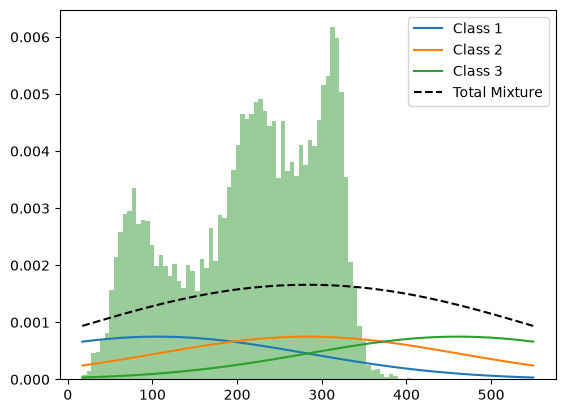

In [4]:
x = bins # use bin edges for x-axis
total_pdf = np.zeros_like(x)

plt.hist(brain_pixels, bins=100, density=True, alpha=0.4, color='g')

for k in range(3):
    # Calculate weighted Gaussian
    weighted_pdf = pi[k] * scipy.stats.norm.pdf(x, mu[k], sigma[k])
    total_pdf += weighted_pdf
    plt.plot(x, weighted_pdf, label=f'Class {k+1}')

# Plot total weighted sum
plt.plot(x, total_pdf, 'k--', label='Total Mixture')
plt.legend()
plt.show()

### Results

The figure shows the histogram of the brain pixel intensities together with the three initial Gaussians, each scaled by its prior weight $\pi_k = \tfrac{1}{3}$, and their sum (dashed line). Since the histogram is normalized to unit area, it can be compared directly with the mixture density.

The initial model fits the data poorly. All three Gaussians are very wide ($\sigma_k = 177.5$), so the total mixture is a broad, flat curve that does not reproduce the three tissue peaks. Moreover, the third Gaussian ($\mu_3 = 460.9$) is centred in an almost empty part of the histogram. This happens because the intensity range used for the initialization is set by a few very bright outlier pixels: the maximum intensity is 549.7, while only 5 of the 13 272 brain pixels exceed 400 and 99% lie below 345.6. These outliers are too few to be visible in the histogram, but they stretch the range over which the three intervals are defined.

## Task 4: Compute weights


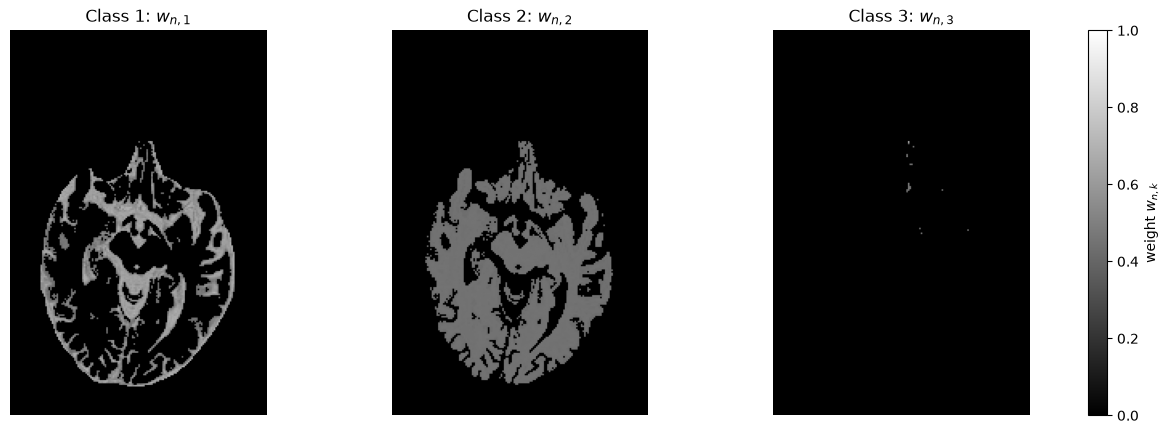

In [5]:
# Calculate probabilities for each class
w = np.zeros((len(brain_pixels), 3))
for k in range(3):
    w[:, k] = pi[k] * scipy.stats.norm.pdf(brain_pixels, mu[k], sigma[k])

# Normalize weights so they sum to 1 for each pixel
w_sum = np.sum(w, axis=1)
w = w / w_sum[:, np.newaxis]

# Assign class based on highest probability
segmentation = np.argmax(w, axis=1)

# Show the weight values w_{n,k}, only on the pixels assigned to class k
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for k in range(3):
    img = np.zeros_like(data, dtype=float)                      # background stays 0
    img[data > 0] = np.where(segmentation == k, w[:, k], 0)     # weight if assigned to k, else 0
    im = axes[k].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[k].set_title(f'Class {k+1}: $w_{{n,{k+1}}}$')
    axes[k].axis('off')
fig.colorbar(im, ax=axes, fraction=0.02, label='weight $w_{n,k}$')
plt.show()

In [6]:
for k in range(3):
    print(f"class {k+1}: {np.sum(segmentation == k)} pixels")

class 1: 4719 pixels
class 2: 8533 pixels
class 3: 20 pixels


### Results

For each brain pixel we computed the posterior probability $w_{n,k}$ of belonging to class $k$, using the initial parameters from Task 2. Each panel shows the pixels assigned to class $k$ (the class with the highest weight), with brightness equal to their weight $w_{n,k}$; all other pixels are black. This corresponds to the segmentation at the starting point, before any parameter has been estimated.

Since all three Gaussians have the same variance and the same prior weight, each pixel is assigned to the class whose mean is closest to its intensity. The class boundaries therefore lie halfway between the initial means, at intensities of about 194.6 and 372.1. This gives a poor segmentation:

- **Class 1** ($d_n < 194.6$) contains the cerebrospinal fluid, but also the darker parts of the grey matter.
- **Class 2** ($194.6 < d_n < 372.1$) contains most of the grey matter together with essentially all of the white matter.
- **Class 3** ($d_n > 372.1$) is almost empty: only 20 of the 13 272 pixels are assigned to it, all isolated outlier pixels, since its mean (460.9) lies above nearly all intensities.

The weights are also low everywhere. Because the initial Gaussians are very wide, they overlap strongly, and no class is clearly preferred for any pixel: even at the cerebrospinal-fluid peak (intensity ≈ 80) the highest weight is only about 0.62, and at the white-matter peak (≈ 310) it is about 0.45. The pixels therefore appear grey rather than white, with class 2 darker than class 1. This segmentation reflects the initialization rather than the anatomy, so the parameters have to be estimated from the data.

## Task 5: Estimate Maximum Likelihood parameters


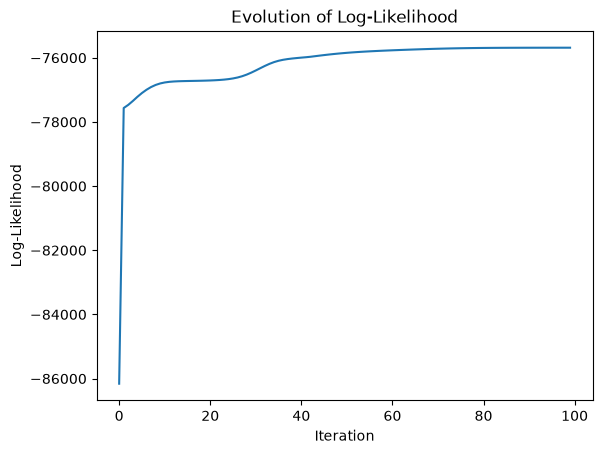

In [7]:
iterations = 100
log_likelihoods = []
N = len(brain_pixels)

for i in range(iterations):
    # --- E-step ---
    pdf_vals = np.zeros((N, 3))
    for k in range(3):
        pdf_vals[:, k] = pi[k] * scipy.stats.norm.pdf(brain_pixels, mu[k], sigma[k])
    
    w_sum = np.sum(pdf_vals, axis=1)
    
    # Calculate log likelihood: log(sum(w_k * N(x | mu_k, sigma_k)))
    log_likelihood = np.sum(np.log(w_sum))
    log_likelihoods.append(log_likelihood)
    
    w = pdf_vals / w_sum[:, np.newaxis]
    
    # --- M-step ---
    for k in range(3):
        N_k = np.sum(w[:, k])
        # Update mean
        mu[k] = np.sum(w[:, k] * brain_pixels) / N_k
        # Update variance
        sigma[k] = np.sqrt(np.sum(w[:, k] * (brain_pixels - mu[k])**2) / N_k)
        # Update prior weight
        pi[k] = N_k / N

# Plot Log-Likelihood evolution
plt.plot(log_likelihoods)
plt.title("Evolution of Log-Likelihood")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.show()

### Results

Starting from the initial parameters of Task 2, we ran 100 iterations of the EM algorithm. Each iteration consists of an E-step, in which the weights $w_{n,k}$ are recomputed with the current parameters, and an M-step, in which the means, variances and prior weights are updated as weighted averages using these weights.

The figure shows the log likelihood $\log p(\mathbf{d} \mid \theta)$ at each iteration. It increases at every step, as guaranteed by EM, from about −86 150 at the start to −75 686 at convergence. The largest gain occurs in the very first iteration (to about −77 600), when the poorly placed initial Gaussians are moved towards the data. After that, the curve flattens around iterations 10–25, rises again around iterations 25–40, and then levels off. The plateau reflects a phase in which the components slowly rearrange themselves between the histogram peaks before settling on the three tissue classes; the curve is essentially flat after about 60–80 iterations, indicating convergence.

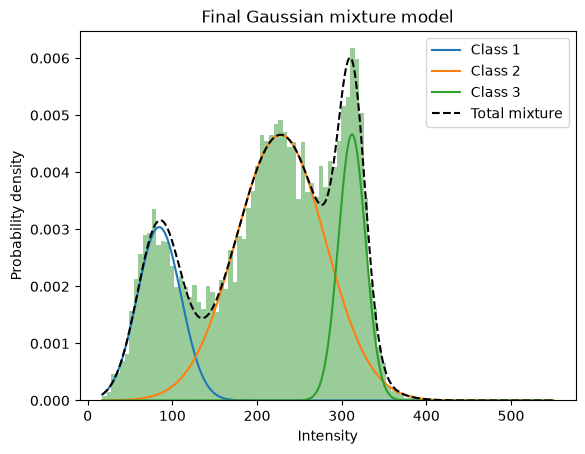

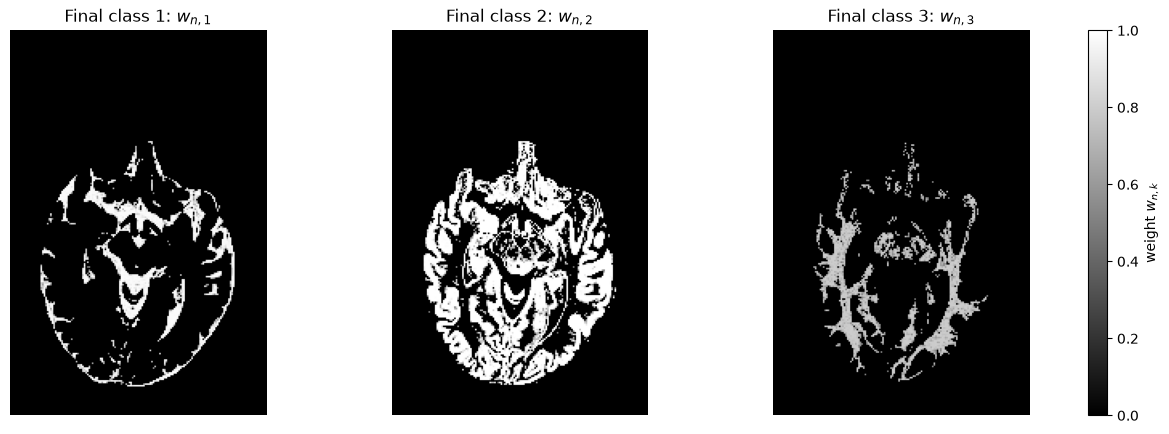

final means: [ 84.39 227.75 312.15]
final sigmas: [25.85 52.79 15.98]
final pi: [0.197 0.616 0.187]


In [8]:
# Final mixture model on the histogram
x = np.linspace(brain_pixels.min(), brain_pixels.max(), 500)
total = np.zeros_like(x)
plt.hist(brain_pixels, bins=100, density=True, alpha=0.4, color='g')
for k in range(3):
    y = pi[k] * norm.pdf(x, mu[k], sigma[k]); total += y
    plt.plot(x, y, label=f'Class {k+1}')
plt.plot(x, total, 'k--', label='Total mixture')
plt.xlabel('Intensity'); plt.ylabel('Probability density')
plt.title('Final Gaussian mixture model'); plt.legend(); plt.show()

# Final weights (same style as Task 4)
w_final = np.stack([pi[k] * norm.pdf(brain_pixels, mu[k], sigma[k]) for k in range(3)], axis=1)
w_final /= w_final.sum(axis=1, keepdims=True)
seg_final = np.argmax(w_final, axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for k in range(3):
    img = np.zeros_like(data, dtype=float)
    img[data > 0] = np.where(seg_final == k, w_final[:, k], 0)
    im = axes[k].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[k].set_title(f'Final class {k+1}: $w_{{n,{k+1}}}$'); axes[k].axis('off')
fig.colorbar(im, ax=axes, fraction=0.02, label='weight $w_{n,k}$')
plt.show()

print("final means:", np.round(mu, 2))
print("final sigmas:", np.round(sigma, 2))
print("final pi:", np.round(pi, 3))

The final Gaussian mixture model is shown on the histogram. The three components now sit on the three histogram peaks, and their weighted sum closely follows the shape of the histogram. The estimated parameters are:

| Class | Tissue | $\mu_k$ | $\sigma_k$ | $\pi_k$ |
|---|---|---|---|---|
| 1 | cerebrospinal fluid | 84.4 | 25.9 | 0.197 |
| 2 | grey matter | 227.7 | 52.8 | 0.616 |
| 3 | white matter | 312.2 | 16.0 | 0.187 |

Compared with the initialization ($\mu_k$ = 105.8, 283.4, 460.9 and $\sigma_k$ = 177.5 for all classes), the means have moved onto the tissue peaks and the standard deviations have become much smaller, so the Gaussians now describe the individual tissues instead of spanning the whole intensity range.

The final weight maps show a segmentation that corresponds to the anatomy: class 1 contains the ventricles and the cerebrospinal fluid around the brain, class 2 the cortical grey matter and deep grey structures, and class 3 the white matter. For classes 1 and 2, most pixels now have weights close to 1, meaning that they are classified with high confidence. The white-matter weights are lower (about 0.6–0.8). The grey-matter Gaussian is wide ($\sigma_2 = 52.8$) and has the largest prior weight ($\pi_2 = 0.616$), so its tail still overlaps the narrow white-matter peak ($\sigma_3 = 16.0$), and even typical white-matter intensities keep a noticeable probability of being grey matter. The broad grey-matter component also absorbs many intermediate intensities between the tissue peaks, such as pixels at tissue boundaries that contain more than one tissue (partial volume effect)..

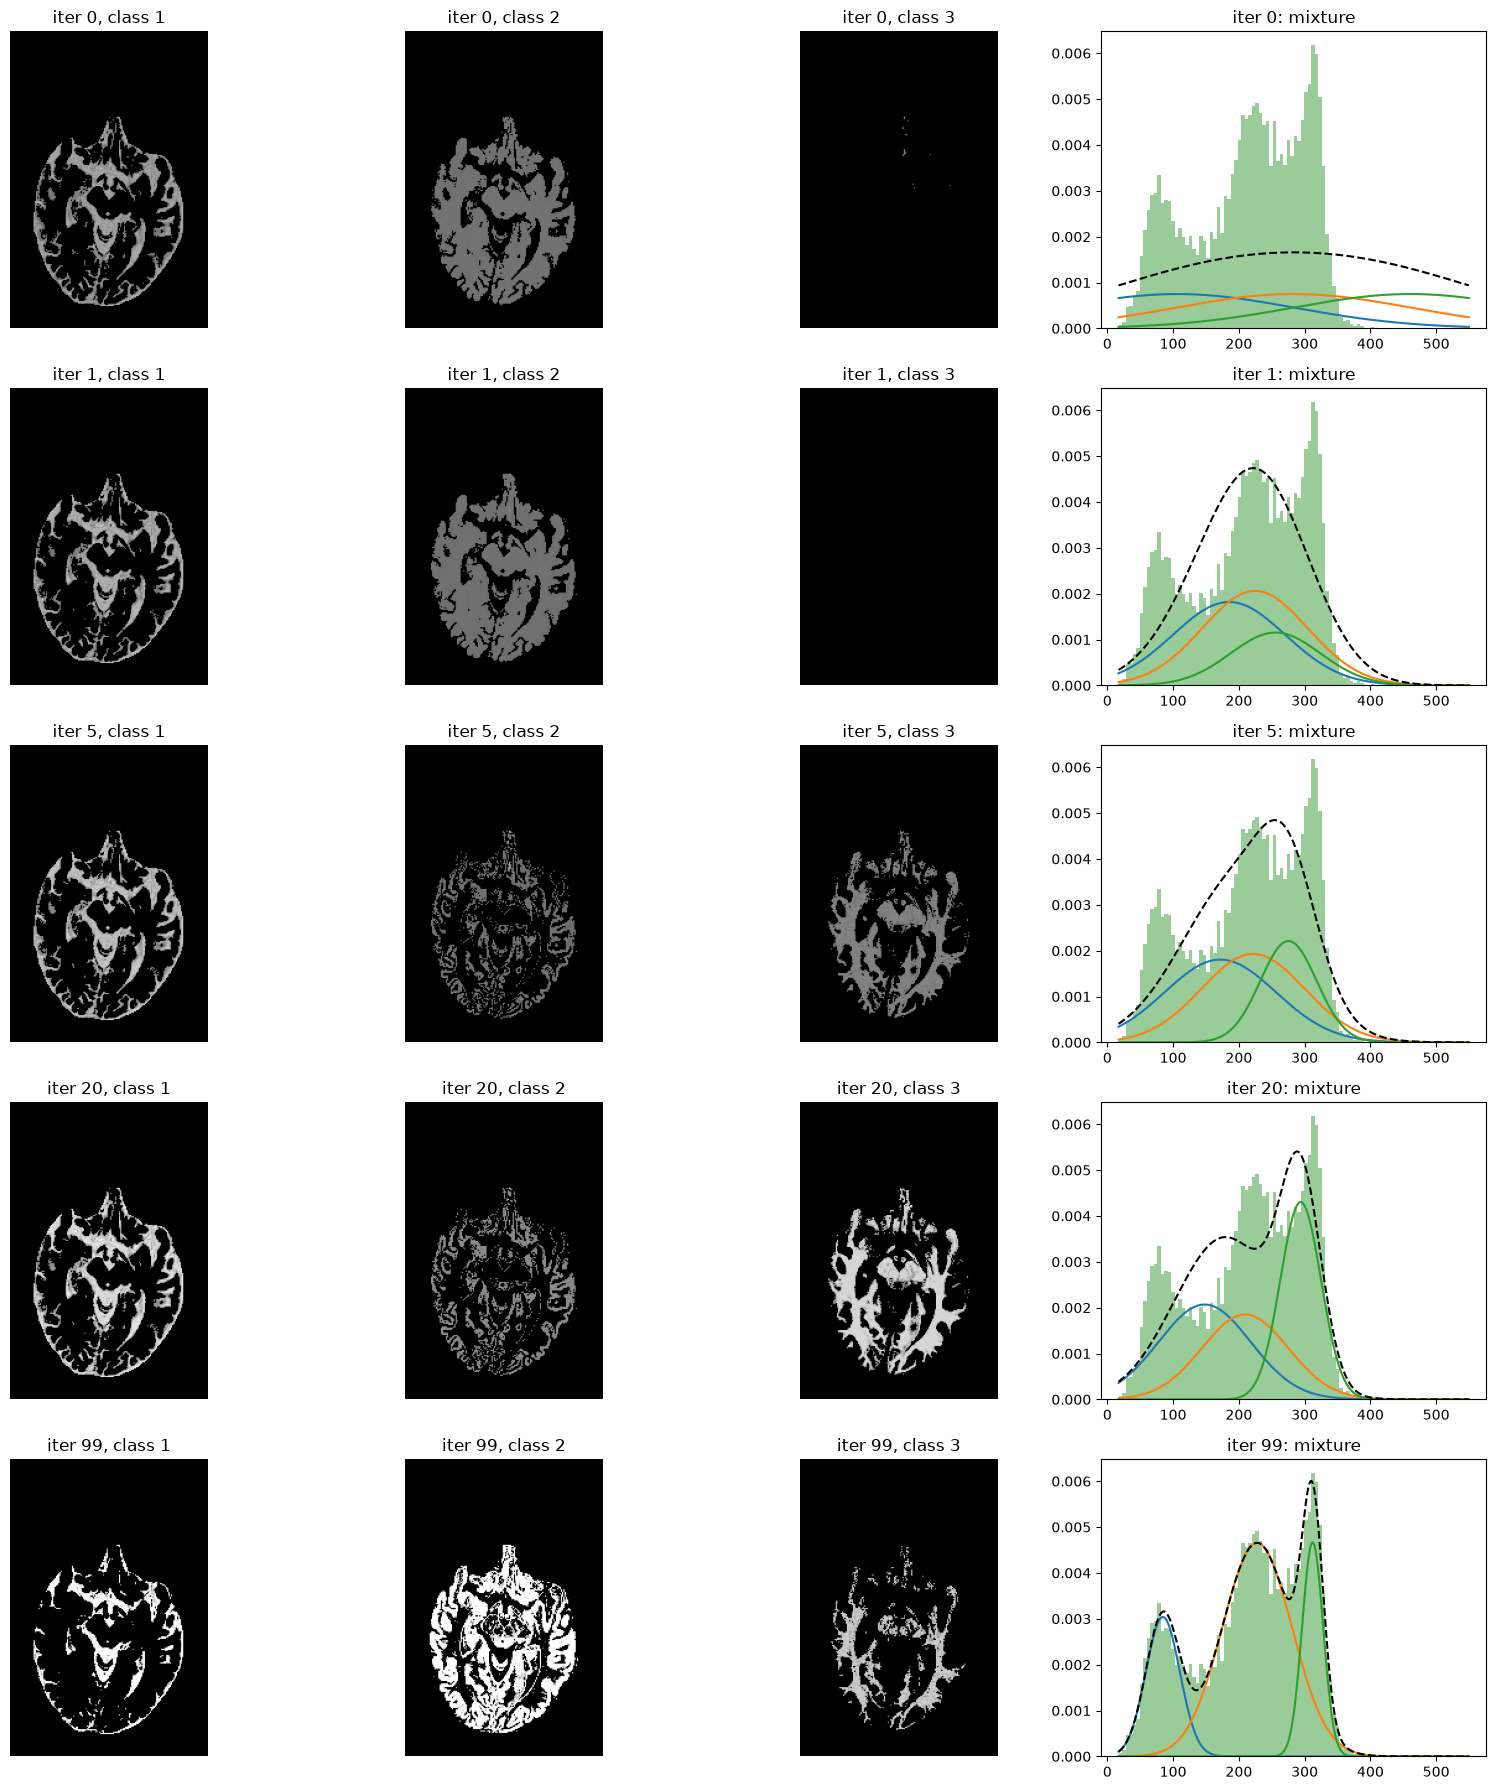

In [9]:
snap_iters = [0, 1, 5, 20, 99]          # iterations to show

# Same min/max initialisation as Task 2 (separate variables)
w0 = (brain_pixels.max() - brain_pixels.min()) / 3
m_ = np.array([brain_pixels.min() + w0 * (k + 0.5) for k in range(3)])
s_ = np.full(3, w0)
p_ = np.full(3, 1/3)

snaps = {}
for it in range(100):
    pdf = np.stack([p_[k] * norm.pdf(brain_pixels, m_[k], s_[k]) for k in range(3)], axis=1)
    w_ = pdf / pdf.sum(axis=1, keepdims=True)                 # E-step
    if it in snap_iters:
        snaps[it] = (w_.copy(), m_.copy(), s_.copy(), p_.copy())
    Nk = w_.sum(axis=0)                                       # M-step
    m_ = (w_ * brain_pixels[:, None]).sum(axis=0) / Nk
    s_ = np.sqrt((w_ * (brain_pixels[:, None] - m_)**2).sum(axis=0) / Nk)
    p_ = Nk / len(brain_pixels)

x = np.linspace(brain_pixels.min(), brain_pixels.max(), 500)
fig, axes = plt.subplots(len(snap_iters), 4, figsize=(16, 3.6 * len(snap_iters)))
for r, it in enumerate(snap_iters):
    w_, m, s, p = snaps[it]
    seg = np.argmax(w_, axis=1)
    for k in range(3):                                        # weight maps
        img = np.zeros_like(data, dtype=float)
        img[data > 0] = np.where(seg == k, w_[:, k], 0)
        axes[r, k].imshow(img, cmap='gray', vmin=0, vmax=1); axes[r, k].axis('off')
        axes[r, k].set_title(f'iter {it}, class {k+1}')
    ax = axes[r, 3]                                           # mixture on histogram
    ax.hist(brain_pixels, bins=100, density=True, alpha=0.4, color='g')
    tot = np.zeros_like(x)
    for k in range(3):
        y = p[k] * norm.pdf(x, m[k], s[k]); tot += y; ax.plot(x, y)
    ax.plot(x, tot, 'k--'); ax.set_title(f'iter {it}: mixture')
plt.tight_layout(); plt.show()

To illustrate how EM reaches this solution, the figure shows the weight maps and the mixture model at iterations 0, 1, 5, 20 and 99. At iteration 0 the segmentation is the poor initial one, with class 3 almost empty. After the first iteration the three Gaussians have become much narrower and moved into the range of the data, but they are still bunched together in the middle of the histogram, forming a single broad hump, and class 3 is still empty. By iteration 5 the third component has moved towards the bright end and starts to capture the white matter. At iteration 20 the classes are not yet in their final roles: class 1 covers the cerebrospinal fluid together with darker grey matter, class 3 covers both grey and white matter, and class 2 is left with mainly the boundary pixels in between. Between iterations 20 and 99 the components rearrange themselves, with class 2 taking over the grey-matter peak and class 3 narrowing onto the white-matter peak. This rearrangement corresponds to the plateau and the second rise in the log-likelihood curve. By the last iteration each component sits on its own histogram peak and the segmentation corresponds to the three tissues.

## Task 6: Vary only one model parameter

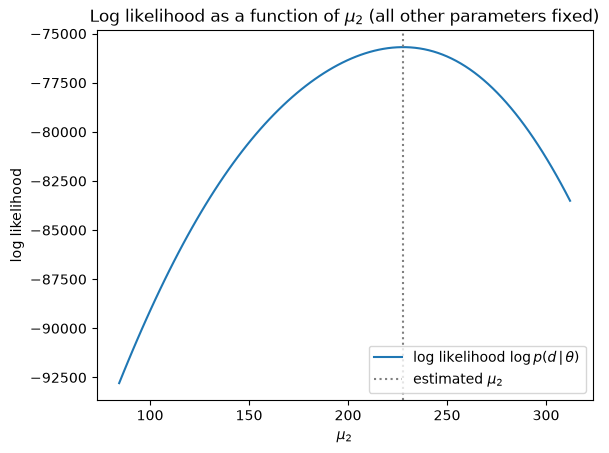

estimated mu_2: 227.74864093256903
mu_2 at the peak of the curve: 227.02912410446737


In [10]:
mu_hat    = np.array(mu, dtype=float)      
sigma_hat = np.array(sigma, dtype=float)   
pi_hat    = np.array(pi, dtype=float)
d = brain_pixels.astype(float)

def log_lik(mu_, sigma_, pi_):
    """log p(d | theta) = sum over voxels of log( sum over classes of pi_k * N(d_n | mu_k, sigma_k^2) )"""
    p = sum(pi_[k] * norm.pdf(d, mu_[k], sigma_[k]) for k in range(3))
    return np.sum(np.log(p))

mu2_grid = np.linspace(mu_hat[0], mu_hat[2], 100)
LL = []
for m in mu2_grid:
    mu_try = mu_hat.copy()
    mu_try[1] = m                      # change mu_2 only
    LL.append(log_lik(mu_try, sigma_hat, pi_hat))
LL = np.array(LL)

plt.plot(mu2_grid, LL, label=r'log likelihood $\log p(d\,|\,\theta)$')
plt.axvline(mu_hat[1], color='gray', ls=':', label=r'estimated $\mu_2$')
plt.xlabel(r'$\mu_2$')
plt.ylabel('log likelihood')
plt.title(r'Log likelihood as a function of $\mu_2$ (all other parameters fixed)')
plt.legend()
plt.show()

print("estimated mu_2:", mu_hat[1])
print("mu_2 at the peak of the curve:", mu2_grid[np.argmax(LL)])

### Results

To examine the log likelihood around the EM solution, we kept all parameters fixed at their estimated values and varied only the grey-matter mean $\mu_2$, in 100 equally spaced steps between the estimated $\mu_1 = 84.4$ and $\mu_3$. For each value we evaluated

$$ \log p(\mathbf{d} \mid \theta) = \sum_{n=1}^{N} \log \sum_{k=1}^{3} \pi_k \, \mathcal{N}(d_n \mid \mu_k, \sigma_k^2). $$

This gives a one-dimensional slice through the log likelihood along the $\mu_2$ direction, with all other parameters fixed.

The curve is a single smooth hill. Its maximum lies at $\mu_2 = 227.0$ on the grid, which agrees with the EM estimate $\mu_2 = 227.7$ (dotted line) to within one grid step, with a maximum log likelihood of −75 686. This confirms that EM has converged to a maximum of the likelihood: changing $\mu_2$ alone cannot improve the fit.

Moving $\mu_2$ away from its estimate lowers the log likelihood, and more strongly towards $\mu_1$ (about −92 790 at $\mu_2 = \mu_1$) than towards $\mu_3$. When $\mu_2$ approaches $\mu_1$ or $\mu_3$, the grey-matter component overlaps with one of the other components, and the grey-matter intensities in the middle of the histogram are no longer well explained by any class.

## Task 7: Locate Lower bound


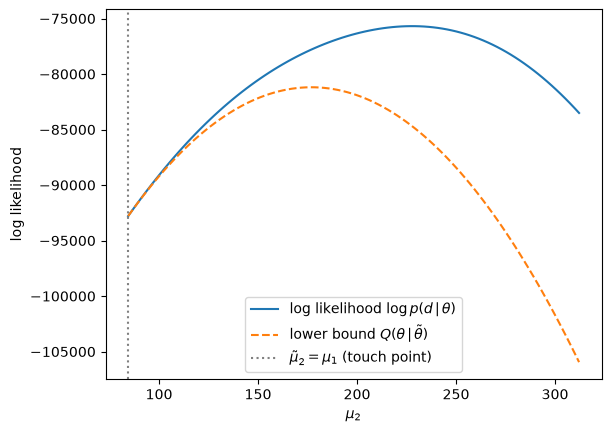

touches at mu_2 = mu_1: True -92789.77590621274 -92789.77590621253
below everywhere: True


In [11]:
import scipy.special

def weights(mu_, sigma_, pi_):
    """E-step: w_{n,k} = pi_k N(d_n | mu_k, sigma_k^2) / sum_k' (...)"""
    p = np.stack([pi_[k] * norm.pdf(d, mu_[k], sigma_[k]) for k in range(3)], axis=1)
    return p / p.sum(axis=1, keepdims=True)

def lower_bound(mu_, sigma_, pi_, w):
    """Q(theta | theta_tilde) from Task 8, with no bias field (all c_m = 0)."""
    var = sigma_**2
    Nk = w.sum(axis=0)                                   # soft counts per class
    Q = -0.5 * sum((w[:, k] * (d - mu_[k])**2).sum() / var[k]
                   + Nk[k] * np.log(var[k]) for k in range(3))
    Q += np.sum(Nk * np.log(pi_))
    Q -= scipy.special.xlogy(w, w).sum()                 # sum of w log w (0·log 0 = 0)
    Q -= len(d) / 2 * np.log(2 * np.pi)
    return Q

# 1. theta_tilde: estimates, but mu_2 set to the estimated mu_1
mu_tilde = mu_hat.copy()
mu_tilde[1] = mu_hat[0]

# 2. E-step at theta_tilde -> frozen weights
w_tilde = weights(mu_tilde, sigma_hat, pi_hat)

# 3. Evaluate the bound along the same mu_2 grid (only mu_2 changes)
Q = []
for m in mu2_grid:
    mu_try = mu_hat.copy()
    mu_try[1] = m
    Q.append(lower_bound(mu_try, sigma_hat, pi_hat, w_tilde))
Q = np.array(Q)

# 4. Plot both curves
plt.plot(mu2_grid, LL, label=r'log likelihood $\log p(d\,|\,\theta)$')
plt.plot(mu2_grid, Q, '--', label=r'lower bound $Q(\theta\,|\,\tilde\theta)$')
plt.axvline(mu_hat[0], color='gray', ls=':', label=r'$\tilde\mu_2 = \mu_1$ (touch point)')
plt.xlabel(r'$\mu_2$')
plt.ylabel('log likelihood')
plt.legend()
plt.show()

# Sanity checks
print("touches at mu_2 = mu_1:", np.isclose(LL[0], Q[0]), LL[0], Q[0])
print("below everywhere:", np.all(Q <= LL + 1e-6))

### Results

On the same figure we added the EM lower bound $Q(\theta \mid \tilde\theta)$, constructed at the parameter vector $\tilde\theta$ in which all parameters are set to their estimated values except $\mu_2$, which is set to the estimated value of $\mu_1 = 84.4$. This places the starting point deliberately far from the maximum, on the left edge of the curve.

The bound is built in two steps. First, the weights $w_{n,k}$ are computed at $\tilde\theta$ (an E-step) and then kept fixed. Second, applying Jensen's inequality to each pixel's log likelihood with these weights gives

$$ \log p(\mathbf{d} \mid \theta) \;\geq\; Q(\theta \mid \tilde\theta) = \sum_{n=1}^{N} \sum_{k=1}^{3} w_{n,k} \log \frac{\pi_k \, \mathcal{N}(d_n \mid \mu_k, \sigma_k^2)}{w_{n,k}}. $$

The bound $Q$ is then evaluated over the same range of $\mu_2$ as the log likelihood, with the weights and all other parameters fixed.

The figure shows the two properties that make this bound useful:

- **It touches the log likelihood at $\tilde\theta$.** At $\mu_2 = \mu_1$ both curves have the value −92 789.78. This happens because the weights are the posteriors at $\tilde\theta$, which makes Jensen's inequality hold with equality there.
- **It lies below the log likelihood everywhere else**, which we verified numerically for all 100 values of $\mu_2$. The gap grows as $\mu_2$ moves away from the touching point, because the fixed weights increasingly differ from the posteriors that would correspond to the new parameters.

With the weights fixed, $\mu_2$ only enters $Q$ through the squared residuals $(d_n - \mu_2)^2$, so the bound is a parabola in $\mu_2$. It is also more sharply curved than the log likelihood: its maximum lies well to the left of the maximum of the log likelihood.

## Task 8: Maximize lower bound



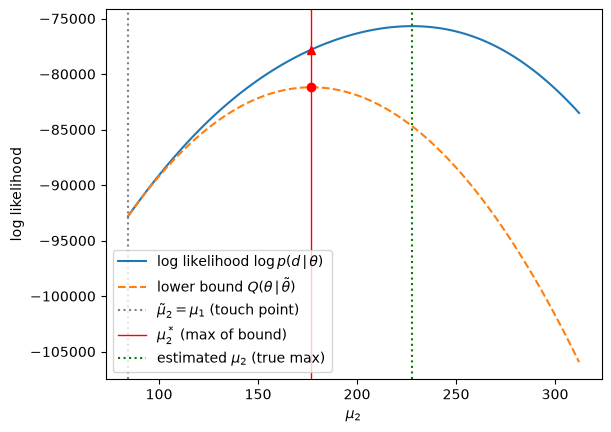

start  mu_2 = mu_1  = 84.39   log lik = -92789.78
new    mu_2*        = 176.94   log lik = -77794.06   bound = -81189.96
target estimated mu_2 = 227.75  log lik = -75686.23
bound max matches numerical argmax of Q: 176.4154048830415
went uphill: True


In [12]:
# Maximum of the lower bound: weighted mean with the frozen weights (eq. 3.35, c_m = 0)
mu2_star = np.sum(w_tilde[:, 1] * d) / np.sum(w_tilde[:, 1])

# Values of both curves at the start (mu_2 = mu_1) and at mu2_star
mu_star = mu_hat.copy(); mu_star[1] = mu2_star
LL_start = LL[0]                                     # real curve at mu_2 = mu_1
LL_star  = log_lik(mu_star, sigma_hat, pi_hat)       # real curve at mu2_star
Q_star   = lower_bound(mu_star, sigma_hat, pi_hat, w_tilde)

# Same figure as Task 7, plus the new point
plt.plot(mu2_grid, LL, label=r'log likelihood $\log p(d\,|\,\theta)$')
plt.plot(mu2_grid, Q, '--', label=r'lower bound $Q(\theta\,|\,\tilde\theta)$')
plt.axvline(mu_hat[0], color='gray', ls=':', label=r'$\tilde\mu_2 = \mu_1$ (touch point)')
plt.axvline(mu2_star, color='red', ls='-', lw=1, label=r'$\mu_2^*$ (max of bound)')
plt.plot(mu2_star, Q_star, 'ro')                     # top of the bound
plt.plot(mu2_star, LL_star, 'r^')                    # real curve at that mu_2
plt.axvline(mu_hat[1], color='green', ls=':', label=r'estimated $\mu_2$ (true max)')
plt.xlabel(r'$\mu_2$'); plt.ylabel('log likelihood'); plt.legend(); plt.show()

print(f"start  mu_2 = mu_1  = {mu_hat[0]:.2f}   log lik = {LL_start:.2f}")
print(f"new    mu_2*        = {mu2_star:.2f}   log lik = {LL_star:.2f}   bound = {Q_star:.2f}")
print(f"target estimated mu_2 = {mu_hat[1]:.2f}  log lik = {LL.max():.2f}")
print("bound max matches numerical argmax of Q:", mu2_grid[np.argmax(Q)])
print("went uphill:", LL_star > LL_start)

### Results

With the weights fixed at $\tilde\theta$, the lower bound depends on $\mu_2$ only through the term

$$ -\frac{1}{2\sigma_2^2} \sum_{n=1}^{N} w_{n,2}\,(d_n - \mu_2)^2 , $$

since the bias field is already corrected ($c_m = 0$). Setting the derivative with respect to $\mu_2$ to zero gives the first line of eq. 3.35:

$$ \mu_2^* = \frac{\sum_n w_{n,2}\, d_n}{\sum_n w_{n,2}} = 176.94 , $$

the weighted mean of the intensities, using the class-2 weights computed at $\tilde\theta$. This agrees with the numerical maximum of the plotted bound (176.42) to within one grid step. In the figure, $\mu_2^*$ is marked by the red vertical line, the maximum of the bound by the red dot, and the log likelihood at $\mu_2^*$ by the red triangle.

The values at the three relevant points are:

| | $\mu_2$ | log likelihood | lower bound |
|---|---|---|---|
| starting point $\tilde\mu_2 = \mu_1$ | 84.39 | −92 789.78 | −92 789.78 |
| maximum of the bound $\mu_2^*$ | 176.94 | −77 794.06 | −81 189.96 |
| maximum of the log likelihood (EM estimate) | 227.75 | −75 686.23 | |

These values follow the chain of inequalities that guarantees the monotonicity of EM:

$$ \log p(\mathbf{d} \mid \theta^*) \;\geq\; Q(\theta^* \mid \tilde\theta) \;\geq\; Q(\tilde\theta \mid \tilde\theta) \;=\; \log p(\mathbf{d} \mid \tilde\theta), $$

$$ -77\,794 \;\geq\; -81\,190 \;\geq\; -92\,790 \;=\; -92\,790 . $$

The first inequality holds because the bound lies below the log likelihood, the second because $\mu_2^*$ maximizes the bound, and the equality because the bound touches the log likelihood at $\tilde\theta$. Maximizing the bound therefore always increases (or at least does not decrease) the log likelihood. Moving from $\tilde\theta$ to $\theta^*$ is exactly one EM iteration restricted to $\mu_2$.

However, $\mu_2^*$ does not reach the maximum of the log likelihood at 227.75. Because the bound is more sharply curved than the log likelihood, its maximum lies closer to the starting point. A single step covers about 65% of the distance to the maximum ($92.6$ of $143.4$), but already about 88% of the possible gain in log likelihood ($15\,000$ of $17\,100$). To reach the maximum, the procedure has to be repeated: recompute the weights at $\mu_2^*$, which gives a new bound touching the log likelihood there, maximize it, and so on. The steps become smaller as the maximum is approached, which explains the slow final convergence of EM observed in the log-likelihood curve.

## Conclusion

We segmented a bias-field-corrected MR brain slice into cerebrospinal fluid, grey matter and white matter by fitting a three-component Gaussian mixture model to the pixel intensities with the EM algorithm.

The prescribed initialization from the minimum and maximum intensity gave a poor starting point: a few bright outlier pixels stretched the intensity range, so the initial Gaussians were very wide, one of them lay in an almost empty part of the histogram, and the initial segmentation did not correspond to the anatomy (only 20 pixels in class 3). Despite this, EM converged to a good solution. After 100 iterations the three components sit on the three histogram peaks (means 84.4, 227.7 and 312.2), the mixture closely reproduces the histogram, and the segmentation separates the three tissues. The log likelihood increased at every iteration, from about −86 150 to −75 686, with a plateau during which the components rearranged themselves between the tissue peaks. The remaining uncertainty is concentrated in the white matter and at tissue boundaries, where the wide grey-matter component overlaps the other classes.

Tasks 6–8 illustrated why EM works. Varying $\mu_2$ alone showed that the estimate lies at the maximum of the log likelihood. The lower bound constructed at a deliberately poor starting point touched the log likelihood there and stayed below it everywhere else, and maximizing it in closed form (a weighted mean) increased the log likelihood from −92 790 to −77 794 in a single step, without reaching the maximum. This confirms the two key properties of EM: each iteration is guaranteed not to decrease the likelihood, but convergence takes several iterations, with progressively smaller steps.

Since the model treats each pixel independently and uses only its intensity, it cannot use spatial information. Overlapping intensity distributions, such as those of grey and white matter, therefore remain a source of misclassification, which could be addressed by adding a spatial prior such as a Markov random field.